# El clasificador: que la máquina distinga la llama del techo

El notebook 03 encuentra las antorchas con una regla escrita a mano: vista tres meses fuera del invierno, que
sature la banda de 2,2 micrones y lejos de Añelo. La regla tiene dos problemas. Deja pasar techos, y por eso
hubo que mirar los focos uno por uno y sacar once. Y descarta las llamas que duran poco, porque les pide tres
meses.

Acá se prueba otra cosa: describir cada foco con números y dejar que un modelo aprenda la diferencia. Lo
importante es de dónde salen los ejemplos. No salen de la regla ni de la revisión a mano, sino de dos fuentes
que no dependen de quien mira:

- **Llama**: un foco a menos de 150 m de un punto de venteo que la empresa declaró ante la Secretaría de Energía.
- **Techo**: un foco dentro del casco de Añelo, lejos de cualquier punto declarado.

La revisión a mano queda guardada como prueba: el modelo no la ve mientras aprende.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np, pandas as pd
from IPython.display import Image, display
from loclab import DATA_PROC, DATA_RAW, FIGURES
from loclab import antorchas, llamas, figuras
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
focos = pd.read_csv(DATA_PROC / "antorchas_focos.csv")
det = pd.read_csv(DATA_PROC / "antorchas_detecciones.csv")
ant = pd.read_csv(DATA_PROC / "antorchas.csv")
rev = pd.read_csv("../data/antorchas_revision.csv")
print(len(focos), "focos ·", int((focos.meses >= llamas.MESES_MIN).sum()), "vistos en dos escenas mensuales o más ·", int(ant.firme.sum()), "antorchas firmes del notebook 03")

756 focos · 359 vistos en dos escenas mensuales o más · 83 antorchas firmes del notebook 03


## 1. Dieciocho números por foco

Para cada foco se recortan las 82 escenas mensuales alrededor (300 m de lado) y se resume cómo se comporta el
lugar:

- **Cuándo aparece**: qué fracción de las veces es en invierno, y en cuántos meses.
- **Cuánto brilla**: la banda de 2,2 micrones, su exceso sobre la de 1,6 y el índice de anomalía térmica.
- **Qué forma tiene la mancha**: su tamaño, si es redonda o una tira, y cuánto se mueve de un mes a otro.
- **Cómo se ve apagado**: el brillo del lugar en los meses sin píxel caliente, y cuánto salta cuando se enciende.
- **Cómo se ve en la foto común**: lo más claro y lo más oscuro del lugar contra su entorno.

El cálculo tarda unos diez minutos; si ya está en `data/processed/antorchas_rasgos.csv` se reutiliza.

In [2]:
ruta = DATA_PROC / "antorchas_rasgos.csv"
if not ruta.exists():
    llamas.rasgos(focos, det).to_csv(ruta, index=False)
t = llamas.etiquetar(pd.read_csv(ruta), antorchas.venteos_declarados(), rev, ant[ant.firme])
print(len(t), "focos descriptos ·", int(t.borde.sum()), "pegados al borde de su ventana, sin recorte")
display(t[["zona", "foco", "meses"] + llamas.RASGOS[:9]].head(4).round(2))

359 focos descriptos · 21 pegados al borde de su ventana, sin recorte


,zona,foco,meses,frac_invierno,frac_meses,b12_mediana,b12_max,exceso_mediana,cociente_b12_b11,pix_mediana,pix_max,deriva_m
0,aguada_del_chanar,0,7,0.43,0.09,1.52,1.52,0.32,1.27,13.0,16.0,4.31
1,aguada_del_chanar,1,7,0.43,0.09,1.51,1.52,0.46,1.48,10.0,11.0,6.00
2,aguada_del_chanar,3,5,0.60,0.06,1.51,1.52,0.39,1.35,8.0,10.0,3.78
3,aguada_del_chanar,4,2,1.00,0.03,0.84,1.00,0.22,1.36,2.5,3.0,3.73


## 2. Los ejemplos para aprender

In [3]:
e = t[t.etiqueta.notna()]
print(f"llamas (a menos de {int(llamas.KM_LLAMA * 1000)} m de un punto declarado): {int((e.etiqueta == 1).sum())}")
print(f"techos (a menos de {llamas.KM_TECHO_ANELO:.0f} km del centro de Añelo): {int((e.etiqueta == 0).sum())}")
print("celdas de 1 km distintas:", e.celda.nunique())
display(e.groupby("etiqueta")[["frac_invierno", "b12_max", "pix_max", "alargada", "tai_max", "visible_claro"]].median().round(2).rename(index={0.0: "techo", 1.0: "llama"}))

llamas (a menos de 150 m de un punto declarado): 54
techos (a menos de 2 km del centro de Añelo): 86
celdas de 1 km distintas: 58


,frac_invierno,b12_max,pix_max,alargada,tai_max,visible_claro
etiqueta,,,,,,
techo,0.91,0.99,2.0,1.53,0.64,1.79
llama,0.42,1.52,28.5,1.13,3.11,1.40


La tabla ya muestra la diferencia: los techos aparecen sobre todo en invierno y brillan menos; las llamas
saturan y dejan una mancha más grande.

## 3. Entrenar y medir sin hacerse trampa

El modelo es un bosque aleatorio. Para medirlo, los ejemplos se parten en cinco por celdas de 1 km, así el
mismo lugar nunca está a la vez entre los que enseñan y los que evalúan, y se repite diez veces. La
probabilidad que recibe cada ejemplo es siempre la de un modelo que no lo vio.

In [4]:
t, peso = llamas.clasificar(t)
e = t[t.etiqueta.notna()]
regla = llamas.regla_sin_lugar(t, focos)
from sklearn.metrics import roc_auc_score
print(f"área bajo la curva en validación cruzada: {roc_auc_score(e.etiqueta, e.p):.3f}")
tabla = pd.DataFrame({"llamas reconocidas": [int(((t.p >= 0.5) & (t.etiqueta == 1)).sum()), int((regla & (t.etiqueta == 1)).sum())],
                      "de": int((t.etiqueta == 1).sum()),
                      "techos que deja pasar": [int(((t.p >= 0.5) & (t.etiqueta == 0)).sum()), int((regla & (t.etiqueta == 0)).sum())],
                      "de ": int((t.etiqueta == 0).sum())}, index=["modelo", "regla a mano, sin el filtro de Añelo"])
display(tabla)
print("lo que más pesa:", ", ".join(f"{k} {v:.2f}" for k, v in peso.head(6).items()))

área bajo la curva en validación cruzada: 0.966


,llamas reconocidas,de,techos que deja pasar,de
modelo,48,54,7,86
"regla a mano, sin el filtro de Añelo",44,54,8,86


lo que más pesa: tai_max 0.20, pix_max 0.15, b12_max 0.11, frac_invierno 0.10, visible_oscuro 0.09, frac_meses 0.06


Con los ejemplos de entrenamiento el modelo es apenas mejor que la regla. La diferencia aparece en la prueba.

## 4. La prueba: lo que se había mirado a mano

Dos grupos que el modelo nunca vio:

- Los focos que la revisión a mano descartó por ser techos: galpones, bases de servicios, zona urbana.
- Las antorchas firmes que no tienen un punto declarado cerca, que a ojo son llamas.

,zona,foco,revision,meses,p,la_regla_lo_aceptaba
0,fortin_de_piedra,4,techos de planta,14,0.31,True
1,loma_campana_este,5,galpon,12,0.24,True
2,loma_campana_este,7,galpon,9,0.05,False
3,loma_campana_oeste,11,base de servicios,13,0.11,True
4,loma_campana_oeste,41,base de servicios,21,0.25,True
5,loma_campana_oeste,64,base de servicios,8,0.06,False
6,ypf_sur_este,0,galpon,33,0.41,True
7,ypf_sur_este,4,galpon,26,0.23,True
8,ypf_sur_este,14,galpon,9,0.11,False
9,ypf_sur_este,74,zona urbana,3,0.14,True


techos descartados a mano: el modelo rechaza 10 de 10 · la regla rechazaba 3
antorchas firmes sin punto declarado: el modelo acepta 37 de 37 · probabilidad mediana 0.96


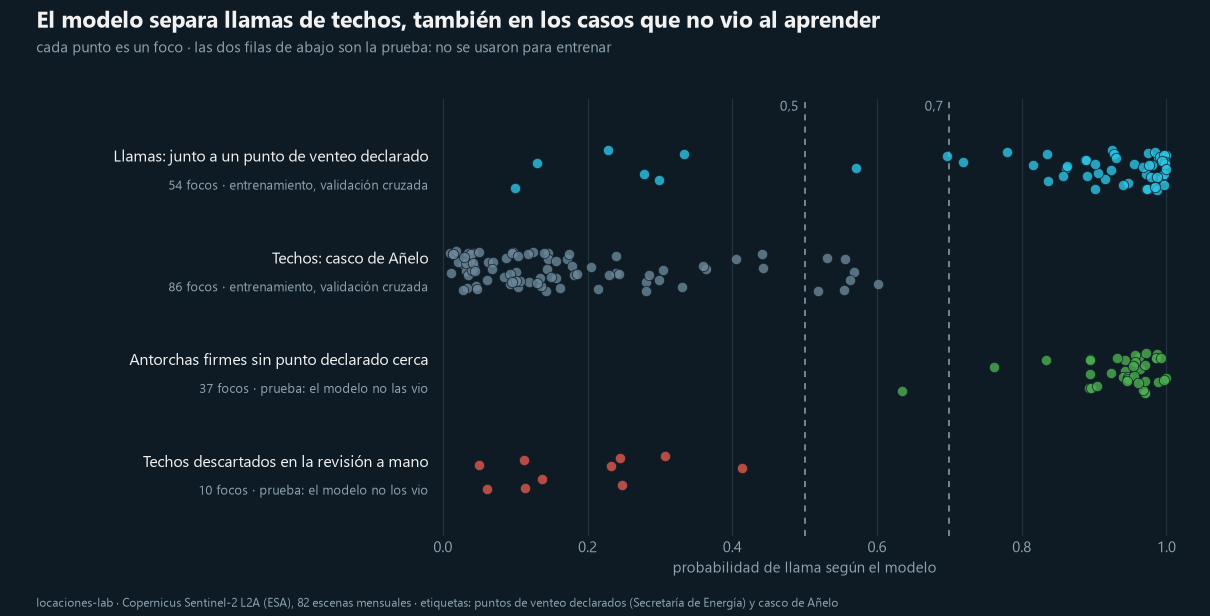

In [5]:
techos = t[t.revision.isin(llamas.VEREDICTOS_TECHO) & ~t.borde]
sin_decl = t[t.firme & (t.km_declarado > 0.5) & ~t.borde]
display(techos[["zona", "foco", "revision", "meses", "p"]].round(2).assign(la_regla_lo_aceptaba=regla[techos.index].values).reset_index(drop=True))
print(f"techos descartados a mano: el modelo rechaza {int((techos.p < 0.5).sum())} de {len(techos)} · la regla rechazaba {int((~regla[techos.index]).sum())}")
print(f"antorchas firmes sin punto declarado: el modelo acepta {int((sin_decl.p >= 0.5).sum())} de {len(sin_decl)} · probabilidad mediana {sin_decl.p.median():.2f}")
display(Image(figuras.llamas_probabilidad(t, FIGURES / "llamas_probabilidad.png", llamas.P_LLAMA)))

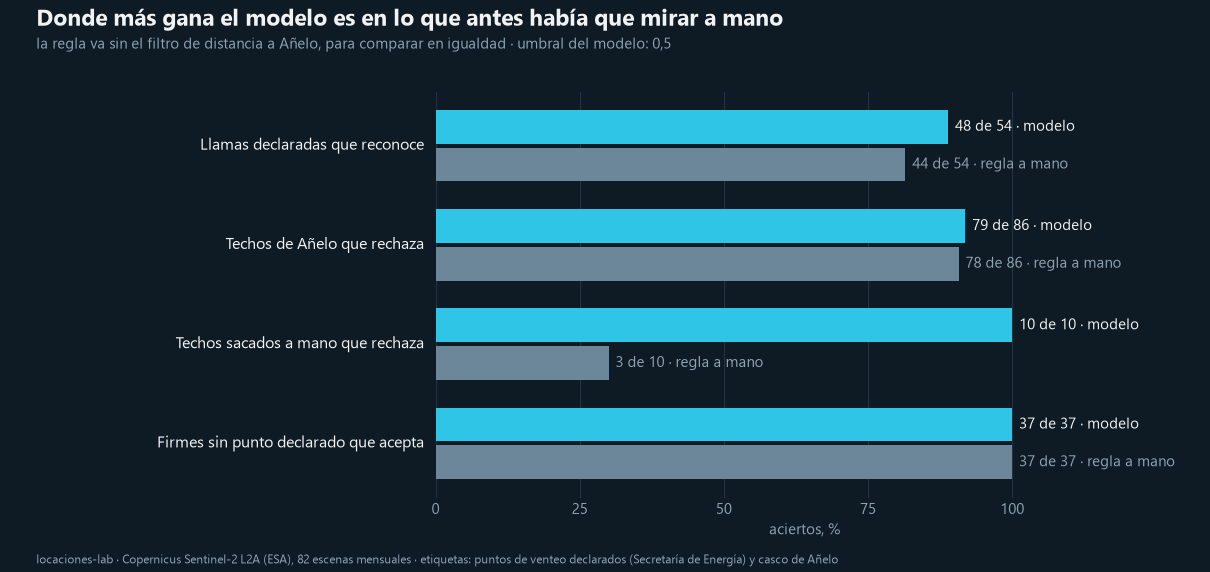

In [6]:
filas = [("Llamas declaradas que reconoce", int((t.etiqueta == 1).sum()), int(((t.p >= 0.5) & (t.etiqueta == 1)).sum()), int((regla & (t.etiqueta == 1)).sum())),
         ("Techos de Añelo que rechaza", int((t.etiqueta == 0).sum()), int(((t.p < 0.5) & (t.etiqueta == 0)).sum()), int((~regla & (t.etiqueta == 0)).sum())),
         ("Techos sacados a mano que rechaza", len(techos), int((techos.p < 0.5).sum()), int((~regla[techos.index]).sum())),
         ("Firmes sin punto declarado que acepta", len(sin_decl), int((sin_decl.p >= 0.5).sum()), int(regla[sin_decl.index].sum()))]
display(Image(figuras.llamas_comparacion(filas, FIGURES / "llamas_comparacion.png")))

La regla aceptaba la mayoría de esos techos: por eso hubo que sacarlos mirando. El modelo los rechaza sin
ayuda, y no pierde ninguna de las antorchas firmes.

## 5. El umbral

Con 0,5 todavía pasan algunos techos de Añelo. ¿Desde qué probabilidad deja de pasar alguno?

In [7]:
filas_u = []
for u in (0.5, 0.6, 0.7, 0.8):
    filas_u.append({"umbral": u, "llamas declaradas": int(((t.p >= u) & (t.etiqueta == 1)).sum()), "techos de Añelo que pasan": int(((t.p >= u) & (t.etiqueta == 0)).sum()),
                    "techos a mano rechazados": int((techos.p < u).sum()), "firmes aceptadas": int((t.p[t.firme & ~t.borde] >= u).sum())})
display(pd.DataFrame(filas_u).set_index("umbral"))
print("antorchas firmes con rasgos:", int((t.firme & ~t.borde).sum()), "de", int(ant.firme.sum()))

,llamas declaradas,techos de Añelo que pasan,techos a mano rechazados,firmes aceptadas
umbral,,,,
0.5,48,7,10,79
0.6,47,1,10,78
0.7,46,0,10,76
0.8,44,0,10,74


antorchas firmes con rasgos: 79 de 83


Desde 0,7 no pasa ningún techo de Añelo, a cambio de perder un par de llamas. Ese es el umbral que se usa
en lo que sigue. Se eligió mirando esta tabla, así que hay que volver a probarlo en una zona nueva antes de
darlo por bueno.

## 6. Lo que la regla perdía: las llamas cortas

Focos que no son antorchas firmes, que el modelo ve como llama con probabilidad de 0,7 o más, lejos de Añelo y
sin repetir entre ventanas vecinas.

In [8]:
tmp = llamas.temporales(t)
tmp.to_csv(DATA_PROC / "antorchas_temporales.csv", index=False)
t.to_csv(DATA_PROC / "antorchas_clasificadas.csv", index=False)
print(len(tmp), "llamas cortas ·", int((tmp.km_declarado <= 0.15).sum()), "de ellas junto a un punto de venteo declarado · mediana de", int(tmp.meses.median()), "escenas con llama")
display(tmp[["zona", "foco", "meses", "frac_invierno", "pix_max", "km_declarado", "p"]].round(2))

12 llamas cortas · 2 de ellas junto a un punto de venteo declarado · mediana de 3 escenas con llama


,zona,foco,meses,frac_invierno,pix_max,km_declarado,p
0,norte_norte,2,3,0.33,17.0,3.07,0.95
1,aguada_pichana_oeste,17,3,0.33,14.0,11.03,0.94
2,aguada_del_chanar,3,5,0.60,10.0,5.90,0.94
3,aguada_pichana_este,0,4,0.50,17.0,0.00,0.91
4,aguada_pichana_oeste,13,4,0.50,23.0,8.57,0.90
5,norte_noreste,13,6,0.67,21.0,6.83,0.89
6,sierras_blancas,5,2,0.00,21.0,0.62,0.88
7,loma_campana_este,18,2,0.50,12.0,0.01,0.86
8,aguada_pichana_este,3,3,0.67,16.0,7.27,0.83
9,aguada_pichana_oeste,2,2,0.00,10.0,9.38,0.80


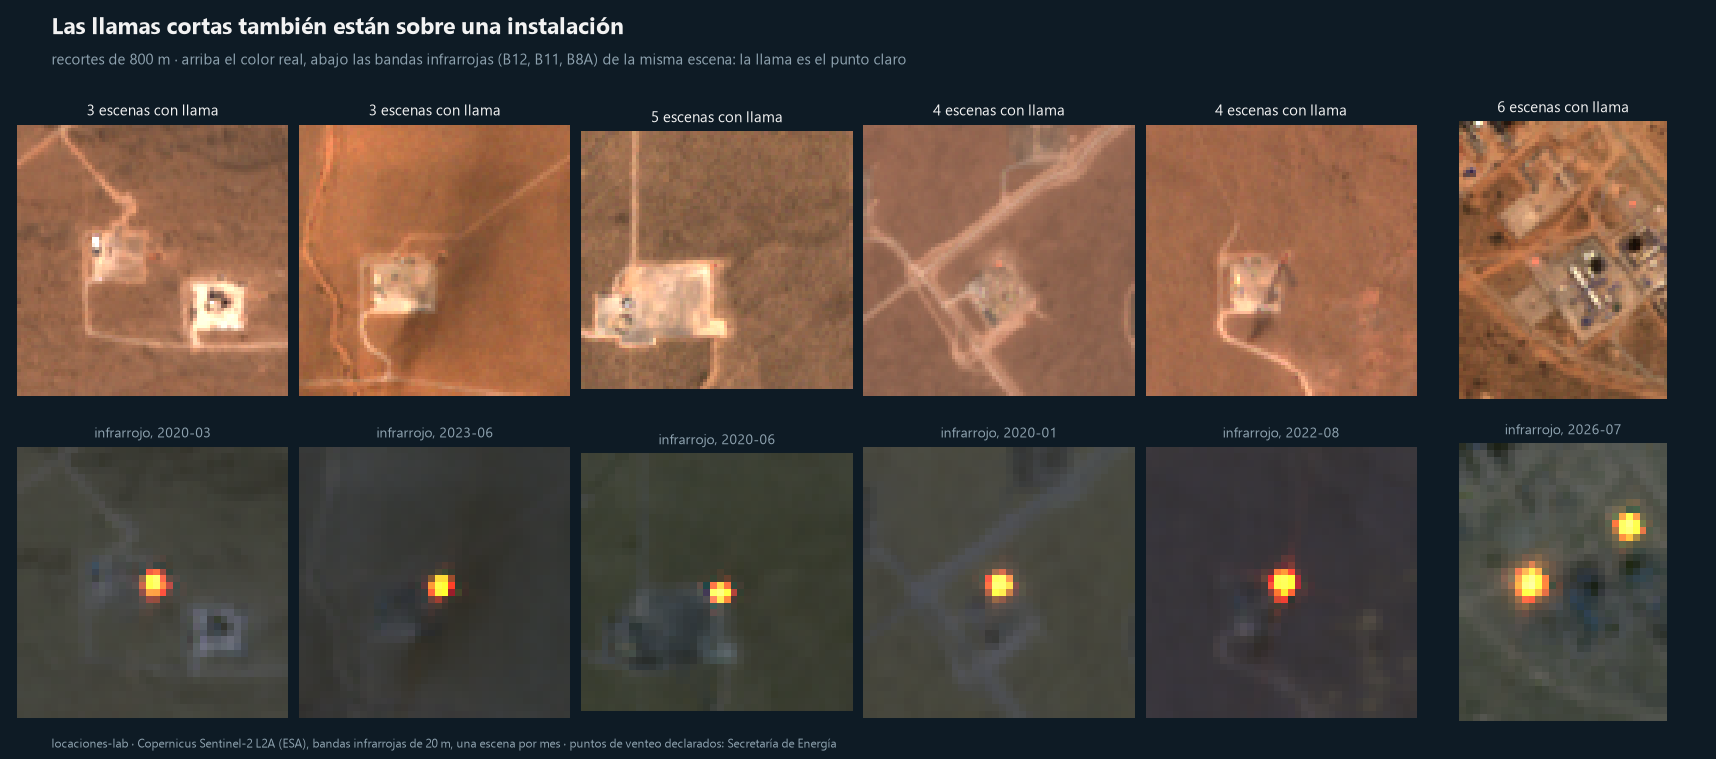

In [9]:
from rasterio.transform import Affine
arriba, abajo, tit, meses_rec = [], [], [], []
for a in tmp.head(6).itertuples():
    d = det[(det.zona == a.zona) & (det.foco == a.foco)]
    mes = d.sort_values("pix").mes.iloc[-1]
    e_ = np.load(DATA_RAW / a.zona / f"{mes}.npz"); m = antorchas.cargar_mes(a.zona, mes)
    rgb = np.dstack([e_[k].astype(np.float32) / 10000 for k in ("red", "green", "blue")])
    c, f = ~Affine.from_gdal(*e_["transform"]) * (a.x, a.y); c, f = int(c), int(f)
    c2, f2 = ~m["transform"] * (a.x, a.y); c2, f2 = int(c2), int(f2)
    sw = np.clip(np.dstack([m["b12"], m["b11"], m["b8a"]]) / 0.9, 0, 1)
    rec = rgb[max(f - 40, 0):f + 40, max(c - 40, 0):c + 40]
    arriba.append(np.clip(rec / np.median(rec) * 0.42, 0, 1))      # el brillo se ajusta con el propio recorte: hay escenas que cubren media ventana
    abajo.append(sw[max(f2 - 20, 0):f2 + 20, max(c2 - 20, 0):c2 + 20])
    tit.append(f"{a.meses} escenas con llama"); meses_rec.append(mes)
display(Image(figuras.antorchas_recortes(arriba, abajo, tit, meses_rec, FIGURES / "llamas_temporales.png", "Las llamas cortas también están sobre una instalación")))

Están sobre locaciones de pozo o plantas y duran de dos a seis escenas. Lo más probable es que sean quemas
temporales, de un pozo en ensayo. En el tablero van como una capa aparte, "quemas temporales", y no se suman
al conteo de antorchas.

## 7. Qué se puede decir y qué no

- **El modelo reemplaza la revisión a mano en lo que se probó.** Rechaza todos los techos que hubo que sacar
  mirando y acepta todas las antorchas firmes sin punto declarado. Son pocos casos: diez y treinta y siete.
- **Todos los techos de entrenamiento son de un solo pueblo.** Los de la prueba están en otras zonas y los
  rechazó, pero falta verlo en otra cuenca o en otro pueblo.
- **El umbral de 0,7 se eligió mirando los resultados.** Hay que validarlo con datos nuevos.
- **Entre 0,5 y 0,7 se confunde.** Mirados uno por uno, de doce focos en esa franja solo cinco parecen llamas;
  el resto son quemas en chacras o techos. Por eso quedan afuera.
- **Los focos pegados al borde de una ventana no se pueden describir** y quedan sin probabilidad.
- **"Quema temporal" es una lectura, no un dato.** El satélite ve una llama corta sobre una locación; que sea
  un ensayo de pozo es lo más probable, no lo único posible.

Los mismos resultados, como archivos, los deja `python scripts/clasificar.py` en `data/processed/`.